# Decision Tree and Random Forest-Machine Learning with python

In [1]:
!pip install opendatasets
import opendatasets as od
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib
import os
%matplotlib inline


In [2]:
pd.set_option("display.max_columns",None)
pd.set_option("display.max_rows",150)
sns.set_style("darkgrid")
matplotlib.rcParams["font.size"]=14
matplotlib.rcParams["figure.figsize"]=(10,5)
matplotlib.rcParams["figure.facecolor"]="#00000000"

In [3]:
# loading the requoired data
#$raw_df=pd.read_csv("/content/cleaned_weather.csv")
od.download("https://www.kaggle.com/jsphyg/weather-dataset-rattle-package")
# {"username":"abdulrasheedadeleke",
#"key":"b2924c897af2f679e705b0291bd0b34c"}

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: abdulrasheedadeleke
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package


100%|██████████| 3.83M/3.83M [00:00<00:00, 244MB/s]

In [4]:
raw_df=pd.read_csv("/content/weather-dataset-rattle-package/weatherAUS.csv")
raw_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  object 
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  object 
 10  WindDir3pm     141232 non-null  object 
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null

In [5]:
# remove any row whose target value is nan
raw_df.dropna(subset=["RainTomorrow"],inplace=True)


av already done some exploratory data analyis with the data when doing ,logistic regression

# Training, Validation and Test Sets

<Axes: title={'center': 'No of Row per year'}, xlabel='Date', ylabel='count'>

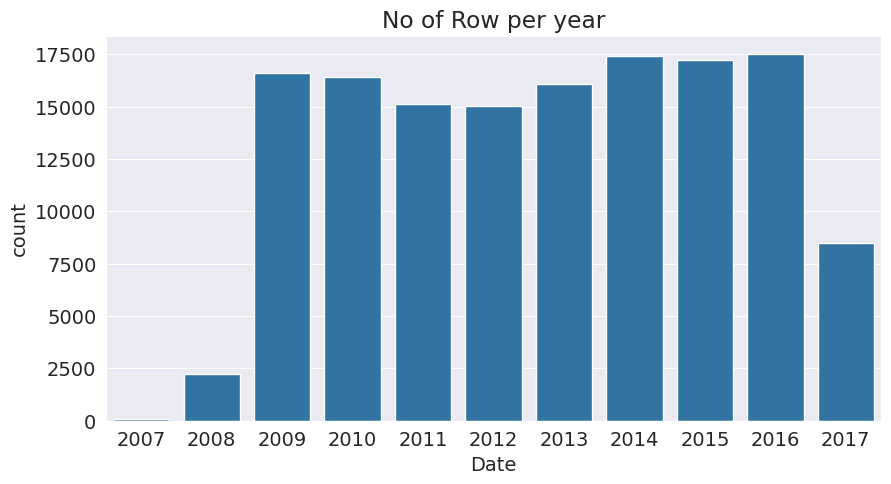

In [6]:
plt.title("No of Row per year")
sns.set_palette("viridis")
sns.countplot(x=pd.to_datetime(raw_df["Date"]).dt.year,data=raw_df)


In [7]:
year=pd.to_datetime(raw_df.Date).dt.year
train_df=raw_df[year<2015]
val_df=raw_df[year==2015]
test_df=raw_df[year>2015]


In [8]:
print("Train_df_shape",train_df.shape)
print("Val_df_shape",val_df.shape)
print("Test_df_shape",test_df.shape)

Train_df_shape (98988, 23)
Val_df_shape (17231, 23)
Test_df_shape (25974, 23)


In [9]:
new_df=raw_df.copy()
input_cols=new_df.drop(["RainTomorrow","Date"],axis=1).columns.tolist()
target_col="RainTomorrow"

In [10]:
# compute Ur input and target cols
train_inputs=train_df[input_cols].copy()
train_targets=train_df[target_col].copy()
val_inputs=val_df[input_cols].copy()
val_targets=val_df[target_col].copy()
test_inputs=test_df[input_cols].copy()
test_targets=test_df[target_col].copy()

In [11]:
# Collect the numerical and categorical columns for preprocessing
numerical_cols=train_inputs.select_dtypes(include=np.number).columns.tolist()
categorical_cols=train_inputs.select_dtypes("object").columns.tolist()

# Data Preprrocessing

In [12]:
# fill the nan in ur numerical variables
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(strategy="mean").fit(raw_df[numerical_cols])

In [13]:
# fill numerical columns
train_inputs[numerical_cols]=imputer.transform(train_inputs[numerical_cols])
val_inputs[numerical_cols]=imputer.transform(val_inputs[numerical_cols])
test_inputs[numerical_cols]=imputer.transform(test_inputs[numerical_cols])

In [14]:
# check if there is still none value in the numerical cols
train_inputs[numerical_cols].isna().sum()

,0
MinTemp,0
MaxTemp,0
Rainfall,0
Evaporation,0
Sunshine,0
WindGustSpeed,0
WindSpeed9am,0
WindSpeed3pm,0
Humidity9am,0
Humidity3pm,0


Scaling Numerical features

In [15]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler().fit(raw_df[numerical_cols])

In [16]:
# Tranform the data
train_inputs[numerical_cols]=scaler.transform(train_inputs[numerical_cols])
val_inputs[numerical_cols]=scaler.transform(val_inputs[numerical_cols])
test_inputs[numerical_cols]=scaler.transform(test_inputs[numerical_cols])

In [17]:
train_inputs[numerical_cols].describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,98988.000000,98988.000000,98988.000000,98988.000000,98988.000000,98988.000000,98988.000000,98988.000000,98988.000000,98988.000000,98988.000000,98988.000000,98988.000000,98988.000000,98988.000000,98988.000000
mean,-0.028669,-0.031395,0.002685,-0.027306,-0.003538,0.016887,0.011138,0.014918,-0.009949,0.000908,-0.017297,-0.015409,-0.028571,-0.020497,-0.024473,-0.023139
std,0.988804,0.981103,1.001245,0.746108,0.768761,0.973340,1.005532,1.002604,0.990686,0.991366,0.947309,0.946536,0.794030,0.785316,0.981779,0.981554
min,-3.230604,-3.839329,-0.277606,-1.305911,-2.016357,-2.500914,-1.574441,-2.117109,-3.613616,-2.475399,-5.228911,-5.152765,-1.536956,-1.655201,-3.525052,-3.861185
25%,-0.731877,-0.748397,-0.277606,-0.398668,-0.033017,-0.661157,-0.787332,-0.640392,-0.621682,-0.696356,-0.598662,-0.619358,-0.497814,-0.552510,-0.737355,-0.733288
50%,-0.060344,-0.116161,-0.277606,0.000000,0.000000,-0.072434,-0.112668,0.041169,0.008198,0.024877,0.000000,0.000000,0.000000,0.000000,-0.059683,-0.099060
75%,0.689274,0.656572,-0.183101,0.031079,0.416540,0.442698,0.561997,0.609137,0.743059,0.649947,0.583530,0.574392,0.541327,0.550182,0.664194,0.636068
max,3.391023,3.494611,43.549180,18.366952,1.765212,6.992233,8.208198,7.765533,1.635390,2.332825,3.285682,3.459288,1.580468,1.652873,3.575104,3.518922


In [18]:
val_inputs[numerical_cols].describe().loc[["min","max"], ["MinTemp","MaxTemp"]]

,MinTemp,MaxTemp
min,-3.183753,-3.712882
max,3.078682,3.115269


# Encoding Categorical Data

In [19]:
from sklearn.preprocessing import OneHotEncoder

In [20]:
train_inputs[categorical_cols].fillna("Unknown",inplace=True)

/tmp/ipykernel_1143/3441669981.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_inputs[categorical_cols].fillna("Unknown",inplace=True)


In [21]:
train_inputs[categorical_cols].isna().sum()

,0
Location,0
WindGustDir,6943
WindDir9am,7323
WindDir3pm,2030
RainToday,1000


In [22]:
Encoder=OneHotEncoder(sparse_output=False,handle_unknown="ignore").fit(raw_df[categorical_cols])

In [23]:
encoder_col=list(Encoder.get_feature_names_out())
encoder_col

['Location_Adelaide',
 'Location_Albany',
 'Location_Albury',
 'Location_AliceSprings',
 'Location_BadgerysCreek',
 'Location_Ballarat',
 'Location_Bendigo',
 'Location_Brisbane',
 'Location_Cairns',
 'Location_Canberra',
 'Location_Cobar',
 'Location_CoffsHarbour',
 'Location_Dartmoor',
 'Location_Darwin',
 'Location_GoldCoast',
 'Location_Hobart',
 'Location_Katherine',
 'Location_Launceston',
 'Location_Melbourne',
 'Location_MelbourneAirport',
 'Location_Mildura',
 'Location_Moree',
 'Location_MountGambier',
 'Location_MountGinini',
 'Location_Newcastle',
 'Location_Nhil',
 'Location_NorahHead',
 'Location_NorfolkIsland',
 'Location_Nuriootpa',
 'Location_PearceRAAF',
 'Location_Penrith',
 'Location_Perth',
 'Location_PerthAirport',
 'Location_Portland',
 'Location_Richmond',
 'Location_Sale',
 'Location_SalmonGums',
 'Location_Sydney',
 'Location_SydneyAirport',
 'Location_Townsville',
 'Location_Tuggeranong',
 'Location_Uluru',
 'Location_WaggaWagga',
 'Location_Walpole',
 'Locat

In [24]:
train_inputs[encoder_col]=Encoder.transform(train_inputs[categorical_cols])
val_inputs[encoder_col]=Encoder.transform(val_inputs[categorical_cols])
test_inputs[encoder_col]=Encoder.transform(test_inputs[categorical_cols])

/tmp/ipykernel_1143/382783866.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_inputs[encoder_col]=Encoder.transform(train_inputs[categorical_cols])
/tmp/ipykernel_1143/382783866.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_inputs[encoder_col]=Encoder.transform(train_inputs[categorical_cols])
/tmp/ipykernel_1143/382783866.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at onc

In [25]:
x_train=train_inputs[encoder_col+numerical_cols].copy()
x_val=val_inputs[encoder_col+numerical_cols].copy()
x_test=test_inputs[encoder_col+numerical_cols].copy()

In [26]:
x_train

,Location_Adelaide,Location_Albany,Location_Albury,Location_AliceSprings,Location_BadgerysCreek,Location_Ballarat,Location_Bendigo,Location_Brisbane,Location_Cairns,Location_Canberra,Location_Cobar,Location_CoffsHarbour,Location_Dartmoor,Location_Darwin,Location_GoldCoast,Location_Hobart,Location_Katherine,Location_Launceston,Location_Melbourne,Location_MelbourneAirport,Location_Mildura,Location_Moree,Location_MountGambier,Location_MountGinini,Location_Newcastle,Location_Nhil,Location_NorahHead,Location_NorfolkIsland,Location_Nuriootpa,Location_PearceRAAF,Location_Penrith,Location_Perth,Location_PerthAirport,Location_Portland,Location_Richmond,Location_Sale,Location_SalmonGums,Location_Sydney,Location_SydneyAirport,Location_Townsville,Location_Tuggeranong,Location_Uluru,Location_WaggaWagga,Location_Walpole,Location_Watsonia,Location_Williamtown,Location_Witchcliffe,Location_Wollongong,Location_Woomera,WindGustDir_E,WindGustDir_ENE,WindGustDir_ESE,WindGustDir_N,WindGustDir_NE,WindGustDir_NNE,WindGustDir_NNW,WindGustDir_NW,WindGustDir_S,WindGustDir_SE,WindGustDir_SSE,WindGustDir_SSW,WindGustDir_SW,WindGustDir_W,WindGustDir_WNW,WindGustDir_WSW,WindGustDir_nan,WindDir9am_E,WindDir9am_ENE,WindDir9am_ESE,WindDir9am_N,WindDir9am_NE,WindDir9am_NNE,WindDir9am_NNW,WindDir9am_NW,WindDir9am_S,WindDir9am_SE,WindDir9am_SSE,WindDir9am_SSW,WindDir9am_SW,WindDir9am_W,WindDir9am_WNW,WindDir9am_WSW,WindDir9am_nan,WindDir3pm_E,WindDir3pm_ENE,WindDir3pm_ESE,WindDir3pm_N,WindDir3pm_NE,WindDir3pm_NNE,WindDir3pm_NNW,WindDir3pm_NW,WindDir3pm_S,WindDir3pm_SE,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW,WindDir3pm_nan,RainToday_No,RainToday_Yes,RainToday_nan,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.189528,-0.045912,-0.206727,0.0,0.0,0.295517,0.674441,0.609137,0.113179,-1.417590,-1.400863,-1.159388,1.234088,0.000000,-0.013478,0.016254
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,-0.747494,0.263181,-0.277606,0.0,0.0,0.295517,-1.124665,0.381950,-1.304053,-1.273343,-0.992725,-1.059908,0.000000,0.000000,0.032727,0.376611
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.111443,0.347479,-0.277606,0.0,0.0,0.442698,0.561997,0.836324,-1.618994,-1.032932,-1.414937,-0.932007,0.000000,-0.920073,0.617989,0.218054
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,-0.466387,0.670622,-0.277606,0.0,0.0,-1.176289,-0.337

# Training and Visualizing Decision Trees

Training

In [27]:
from sklearn.tree import DecisionTreeClassifier

In [28]:
model = DecisionTreeClassifier(random_state=42)

In [29]:
%%time
model.fit(x_train,train_targets)

CPU times: user 5.12 s, sys: 0 ns, total: 5.12 s
Wall time: 7.84 s


DecisionTreeClassifier(random_state=42)

Evaluation

In [30]:
from sklearn.metrics import accuracy_score ,confusion_matrix

In [31]:
train_preds=model.predict(x_train)


In [32]:
pd.value_counts(train_preds)

/tmp/ipykernel_1143/1258350197.py:1: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  pd.value_counts(train_preds)


,count
No,76707
Yes,22281


In [33]:
accuracy_score(train_targets,train_preds)

0.9999797955307714

the model seems to be overfitted

In [34]:
model.score(x_val,val_targets)

0.791016191747432

In [35]:
# our dummy model that always predict no has 0.789 accuracy
val_targets.value_counts()/len(val_targets)


,count
RainTomorrow,
No,0.788289
Yes,0.211711


# Visualization

In [36]:
from sklearn.tree import plot_tree,export_text

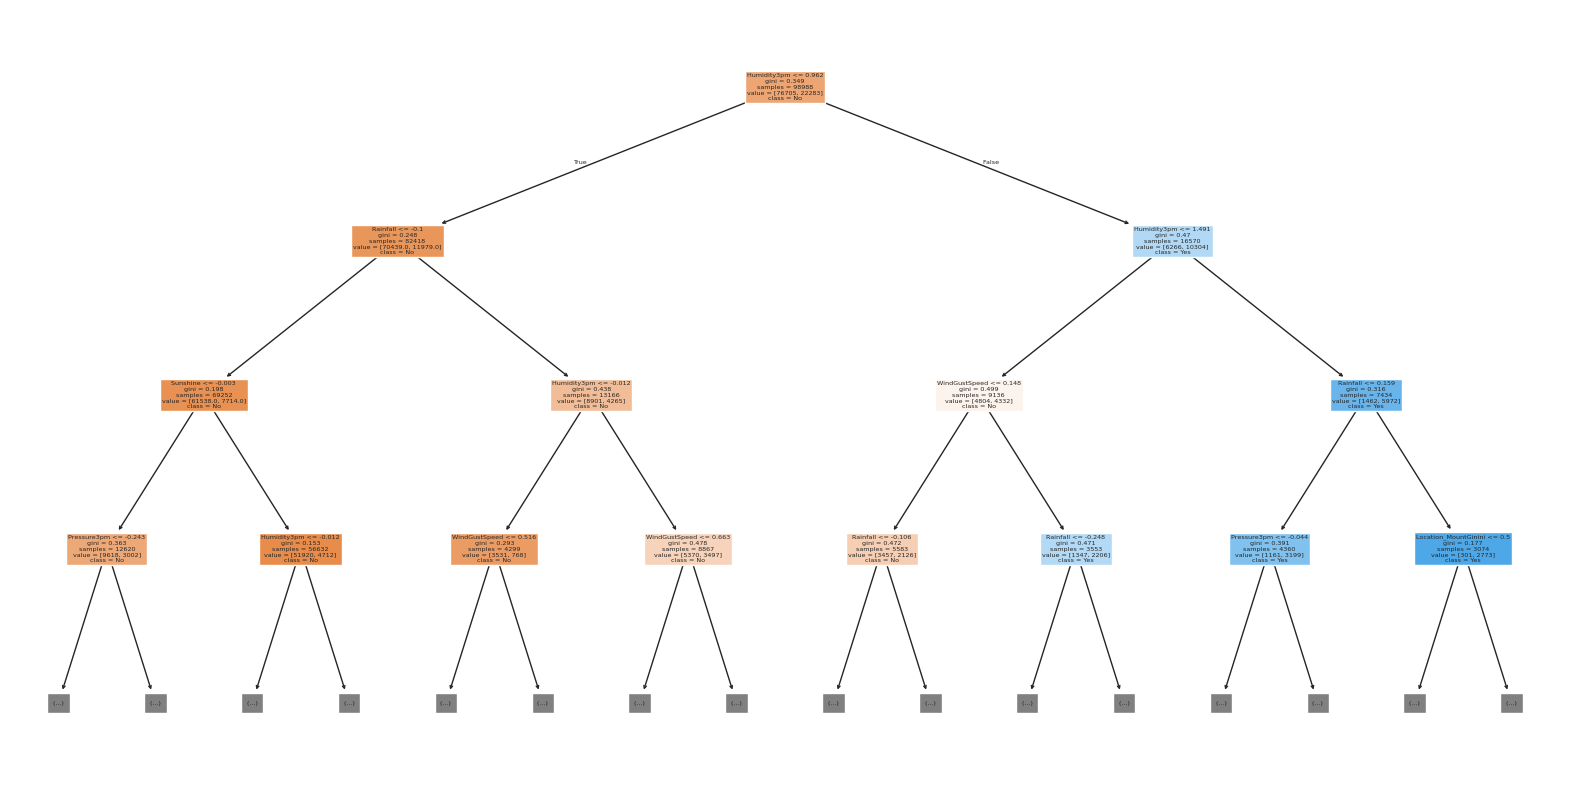

In [37]:
plt.figure(figsize=(20,10))
plot_tree(model,feature_names=x_train.columns,class_names=["No","Yes"],max_depth=3,filled=True)
plt.show()

In [38]:
model.tree_.max_depth

48

In [39]:
tree_text=export_text(model,max_depth=2,feature_names=x_train.columns)
print(tree_text[:5000])

|--- Humidity3pm <= 0.96
|   |--- Rainfall <= -0.10
|   |   |--- Sunshine <= -0.00
|   |   |   |--- truncated branch of depth 36
|   |   |--- Sunshine >  -0.00
|   |   |   |--- truncated branch of depth 46
|   |--- Rainfall >  -0.10
|   |   |--- Humidity3pm <= -0.01
|   |   |   |--- truncated branch of depth 28
|   |   |--- Humidity3pm >  -0.01
|   |   |   |--- truncated branch of depth 35
|--- Humidity3pm >  0.96
|   |--- Humidity3pm <= 1.49
|   |   |--- WindGustSpeed <= 0.15
|   |   |   |--- truncated branch of depth 38
|   |   |--- WindGustSpeed >  0.15
|   |   |   |--- truncated branch of depth 26
|   |--- Humidity3pm >  1.49
|   |   |--- Rainfall <= 0.16
|   |   |   |--- truncated branch of depth 27
|   |   |--- Rainfall >  0.16
|   |   |   |--- truncated branch of depth 24



In [40]:
x_train.columns

Index(['Location_Adelaide', 'Location_Albany', 'Location_Albury',
       'Location_AliceSprings', 'Location_BadgerysCreek', 'Location_Ballarat',
       'Location_Bendigo', 'Location_Brisbane', 'Location_Cairns',
       'Location_Canberra',
       ...
       'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm',
       'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am',
       'Temp3pm'],
      dtype='object', length=119)

In [41]:
model.feature_importances_

array([2.19242359e-03, 2.17867367e-03, 1.36023539e-03, 6.22885439e-04,
       1.64854967e-03, 1.02262670e-03, 6.92155483e-04, 1.68830212e-03,
       1.02363725e-03, 1.57358590e-03, 6.36322383e-04, 2.23208380e-03,
       1.72546894e-03, 2.45784431e-04, 1.11125576e-03, 1.34184565e-03,
       4.79266961e-04, 9.36343832e-04, 1.60420821e-03, 1.30820026e-03,
       9.15835125e-04, 7.53186793e-04, 1.69046042e-03, 2.10332576e-03,
       2.13355777e-04, 6.37676505e-04, 1.42767859e-03, 1.53255562e-03,
       1.37935961e-03, 9.14486087e-04, 8.15220714e-04, 1.51712939e-03,
       1.27063146e-03, 1.81769812e-03, 7.93383474e-04, 1.55963681e-03,
       1.13897841e-03, 1.37125604e-03, 1.14673833e-03, 5.36517930e-04,
       1.48508337e-03, 1.57002724e-04, 1.05408803e-03, 1.68528210e-03,
       1.50739627e-03, 1.49697841e-03, 2.77134406e-03, 2.29567533e-03,
       4.69926199e-04, 1.55421320e-03, 1.56056880e-03, 2.32359673e-03,
       3.48907190e-03, 2.37725327e-03, 2.49649867e-03, 2.40318997e-03,
      

In [42]:
importance_df =pd.DataFrame({
    "feature":x_train.columns,
    "importance":model.feature_importances_
}).sort_values("importance",ascending=False)

In [43]:
importance_df.head(10)

,feature,importance
112,Humidity3pm,0.261093
114,Pressure3pm,0.062534
105,Rainfall,0.059065
108,WindGustSpeed,0.054618
107,Sunshine,0.050047
111,Humidity9am,0.039789
103,MinTemp,0.035371
113,Pressure9am,0.034972
117,Temp9am,0.033066
118,Temp3pm,0.032112


<Axes: title={'center': 'Feature Importance'}, xlabel='importance', ylabel='feature'>

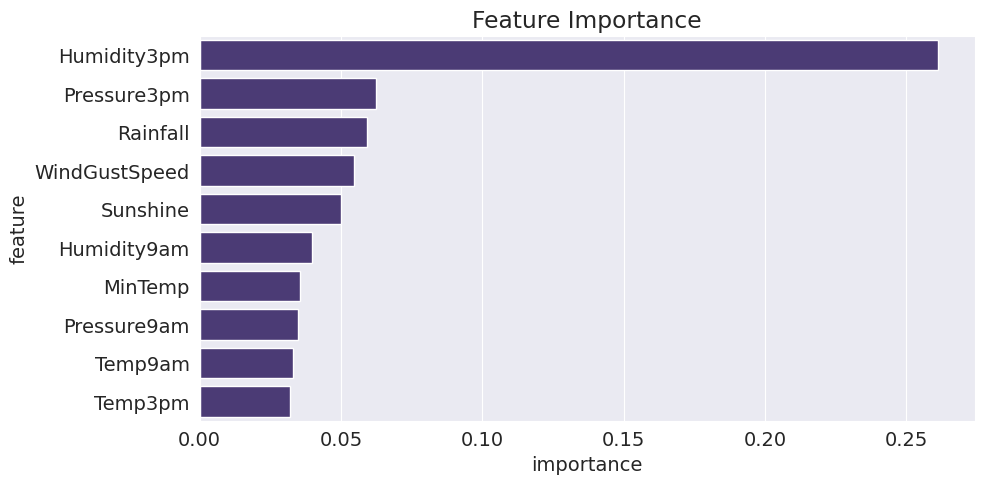

In [44]:
plt.title("Feature Importance")
sns.barplot(data=importance_df.head(10),x="importance",y="feature")

In [45]:
?DecisionTreeClassifier

In [46]:
model=DecisionTreeClassifier(max_depth=3,random_state=42)

In [47]:
model.fit(x_train,train_targets)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [48]:
model.score(x_train,train_targets)

0.8291308037337859

In [49]:
model.score(x_val,val_targets)

0.8334397307178921

In [50]:
model.score(x_test,test_targets)

0.8235928235928236

In [51]:
model.classes_

array(['No', 'Yes'], dtype=object)

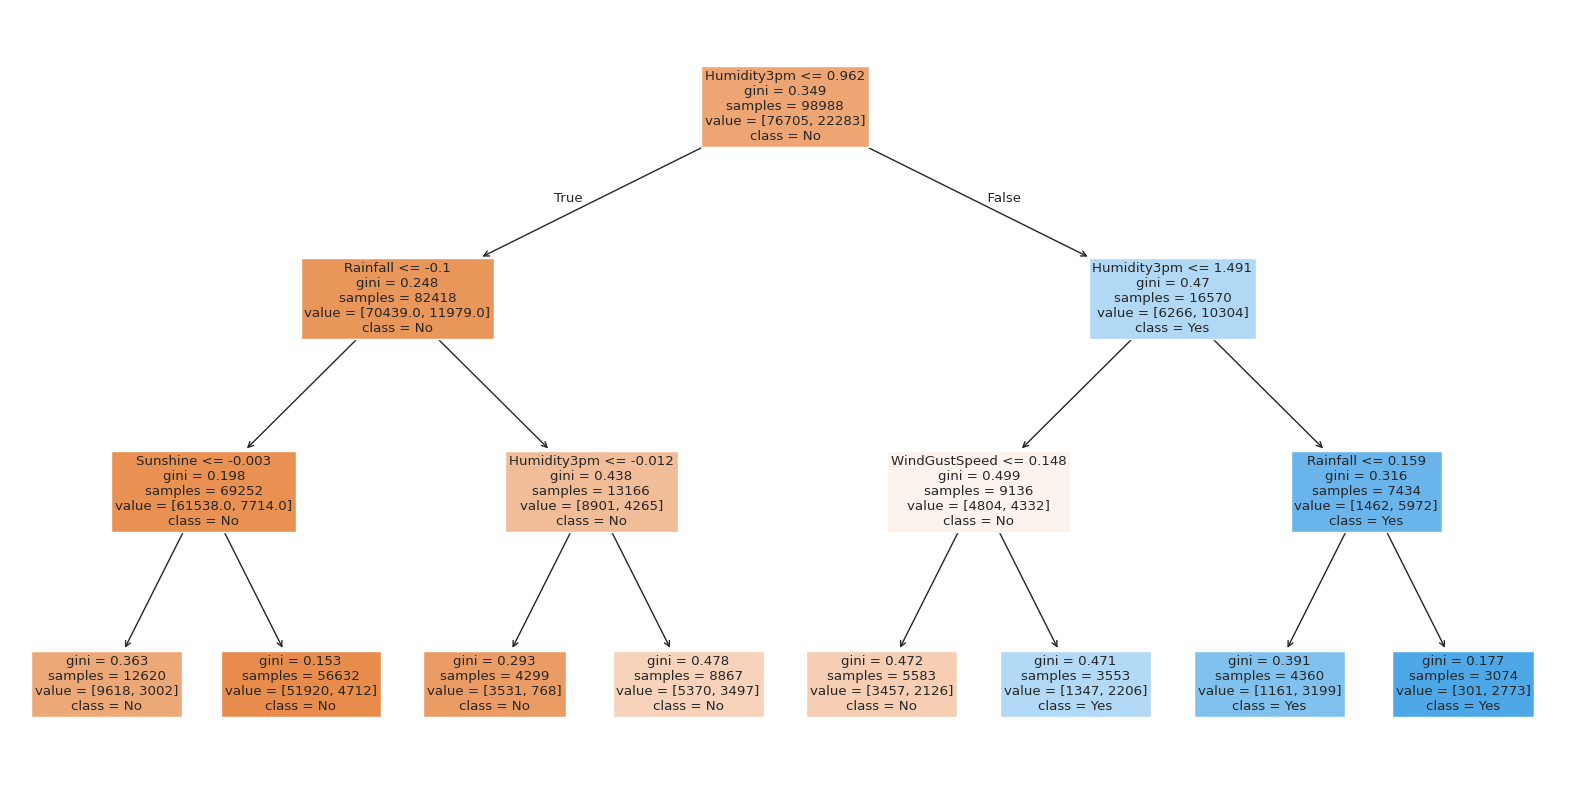

In [52]:
plt.figure(figsize=(20,10))
plot_tree(model,feature_names=x_train.columns,filled=True,class_names=model.classes_,max_depth=4)
plt.show()
#

In [53]:
print(export_text(model,feature_names=x_train.columns))

|--- Humidity3pm <= 0.96
|   |--- Rainfall <= -0.10
|   |   |--- Sunshine <= -0.00
|   |   |   |--- class: No
|   |   |--- Sunshine >  -0.00
|   |   |   |--- class: No
|   |--- Rainfall >  -0.10
|   |   |--- Humidity3pm <= -0.01
|   |   |   |--- class: No
|   |   |--- Humidity3pm >  -0.01
|   |   |   |--- class: No
|--- Humidity3pm >  0.96
|   |--- Humidity3pm <= 1.49
|   |   |--- WindGustSpeed <= 0.15
|   |   |   |--- class: No
|   |   |--- WindGustSpeed >  0.15
|   |   |   |--- class: Yes
|   |--- Humidity3pm >  1.49
|   |   |--- Rainfall <= 0.16
|   |   |   |--- class: Yes
|   |   |--- Rainfall >  0.16
|   |   |   |--- class: Yes



In [54]:
def max_depth_error(md):
  model=DecisionTreeClassifier(max_depth=md,random_state=42)
  model.fit(x_train,train_targets)
  train_error =1-model.score(x_train,train_targets)
  val_error = 1- model.score(x_val,val_targets)
  return{
      "Max_depth": md,
      "Trainnig Error": train_error,
      "Validation Error":val_error
  }

In [55]:
error_df=pd.DataFrame([max_depth_error(md) for md in range(1,21)])

In [56]:
error_df

,Max_depth,Trainnig Error,Validation Error
0,1,0.184315,0.177935
1,2,0.179547,0.172712
2,3,0.170869,0.166560
3,4,0.165707,0.164355
4,5,0.160676,0.159074
5,6,0.156271,0.157275
6,7,0.153312,0.154663
7,8,0.147806,0.157971
8,9,0.140916,0.156636
9,10,0.132935,0.157913


In [57]:
error_df.groupby(["Trainnig Error","Validation Error"]).min()

,,Max_depth
Trainnig Error,Validation Error,
0.032267,0.185770,20
0.039904,0.185131,19
0.048733,0.180721,18
0.058108,0.177123,17
0.068039,0.174917,16
0.079010,0.171145,15
0.089839,0.167431,14
0.101851,0.165400,13
0.113468,0.161511,12


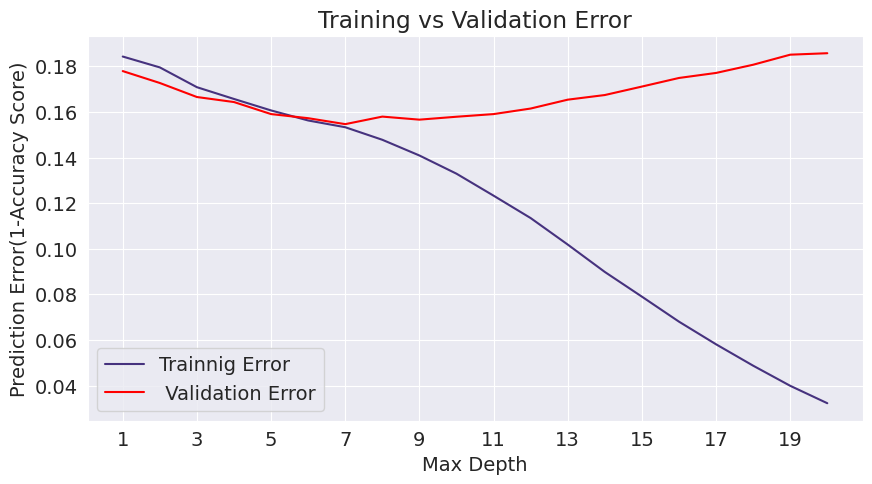

In [58]:
plt.figure()
plt.plot(error_df["Max_depth"],error_df["Trainnig Error"])
plt.plot(error_df["Max_depth"],error_df["Validation Error"],c="red")
plt.legend(["Trainnig Error"," Validation Error"])
plt.xlabel("Max Depth")
plt.xticks(range(1,21,2))
plt.ylabel("Prediction Error(1-Accuracy Score)")
plt.title("Training vs Validation Error")
plt.show()

In [59]:
model=DecisionTreeClassifier(max_depth=7,random_state=42).fit(x_train,train_targets)
model.score(x_train,train_targets),model.score(x_val,val_targets)

(0.8466884874934335, 0.8453368928094713)

In [60]:
model=DecisionTreeClassifier(max_leaf_nodes=128,random_state=42)

In [61]:
model.fit(x_train,train_targets)

DecisionTreeClassifier(max_leaf_nodes=128, random_state=42)

In [62]:
model.score(x_train,train_targets)

0.8480421869317493

In [63]:
model.score(x_val,val_targets)

0.8442342290058615

<function matplotlib.pyplot.show(close=None, block=None)>

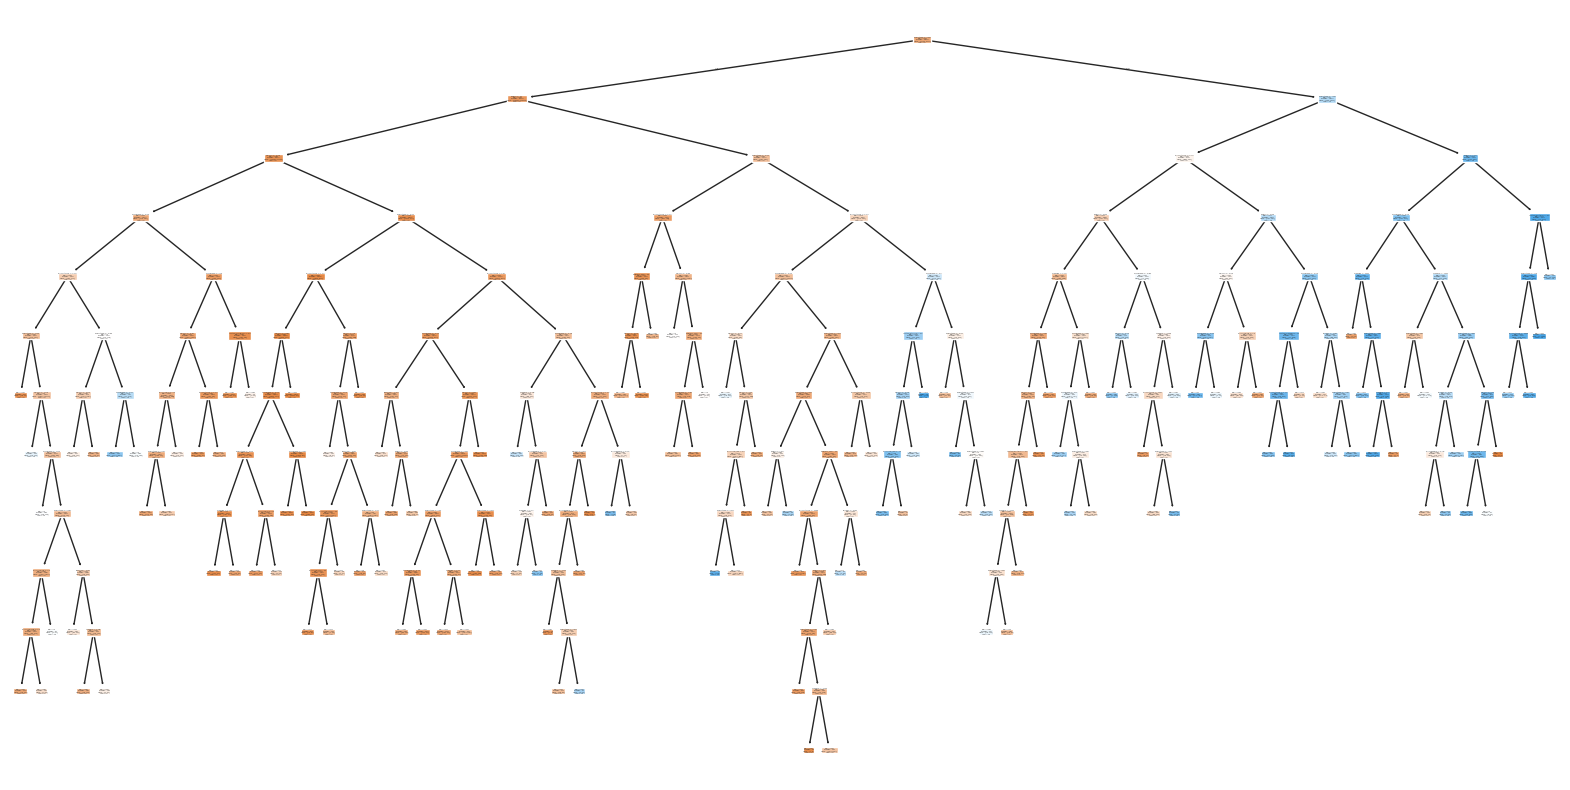

In [64]:
plt.figure(figsize=(20,10))
plot_tree(model,feature_names=x_train.columns,class_names=model.classes_,filled=True)
plt.show

In [65]:
tree_text=export_text(model,feature_names=x_train.columns)
print(tree_text[:6000])

|--- Humidity3pm <= 0.96
|   |--- Rainfall <= -0.10
|   |   |--- Sunshine <= -0.00
|   |   |   |--- Pressure3pm <= -0.24
|   |   |   |   |--- WindGustSpeed <= 0.96
|   |   |   |   |   |--- Humidity3pm <= -1.15
|   |   |   |   |   |   |--- class: No
|   |   |   |   |   |--- Humidity3pm >  -1.15
|   |   |   |   |   |   |--- Sunshine <= -1.82
|   |   |   |   |   |   |   |--- class: Yes
|   |   |   |   |   |   |--- Sunshine >  -1.82
|   |   |   |   |   |   |   |--- Pressure3pm <= -1.58
|   |   |   |   |   |   |   |   |--- class: Yes
|   |   |   |   |   |   |   |--- Pressure3pm >  -1.58
|   |   |   |   |   |   |   |   |--- Humidity3pm <= 0.29
|   |   |   |   |   |   |   |   |   |--- WindDir9am_NE <= 0.50
|   |   |   |   |   |   |   |   |   |   |--- WindDir9am_NNE <= 0.50
|   |   |   |   |   |   |   |   |   |   |   |--- class: No
|   |   |   |   |   |   |   |   |   |   |--- WindDir9am_NNE >  0.50
|   |   |   |   |   |   |   |   |   |   |   |--- class: No
|   |   |   |   |   |   |   |   |   |

# Random Forest

In [66]:
from sklearn.ensemble import RandomForestClassifier

In [67]:
model=RandomForestClassifier(n_jobs=-1,random_state=42)

In [68]:
model.fit(x_train,train_targets)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [69]:
model.score(x_train,train_targets)

0.9999494888269285

In [70]:
model.score(x_val,val_targets)

0.8559572862863444

In [71]:
train_preds=model.predict(x_train)
train_preds

array(['No', 'No', 'No', ..., 'No', 'No', 'No'], dtype=object)

In [72]:
train_probs=model.predict_proba(x_train)
train_probs

array([[0.98, 0.02],
       [0.96, 0.04],
       [0.97, 0.03],
       ...,
       [1.  , 0.  ],
       [1.  , 0.  ],
       [0.95, 0.05]])

In [73]:
len(model.estimators_)

100

In [74]:
model.estimators_[0]

DecisionTreeClassifier(max_features='sqrt', random_state=1608637542)

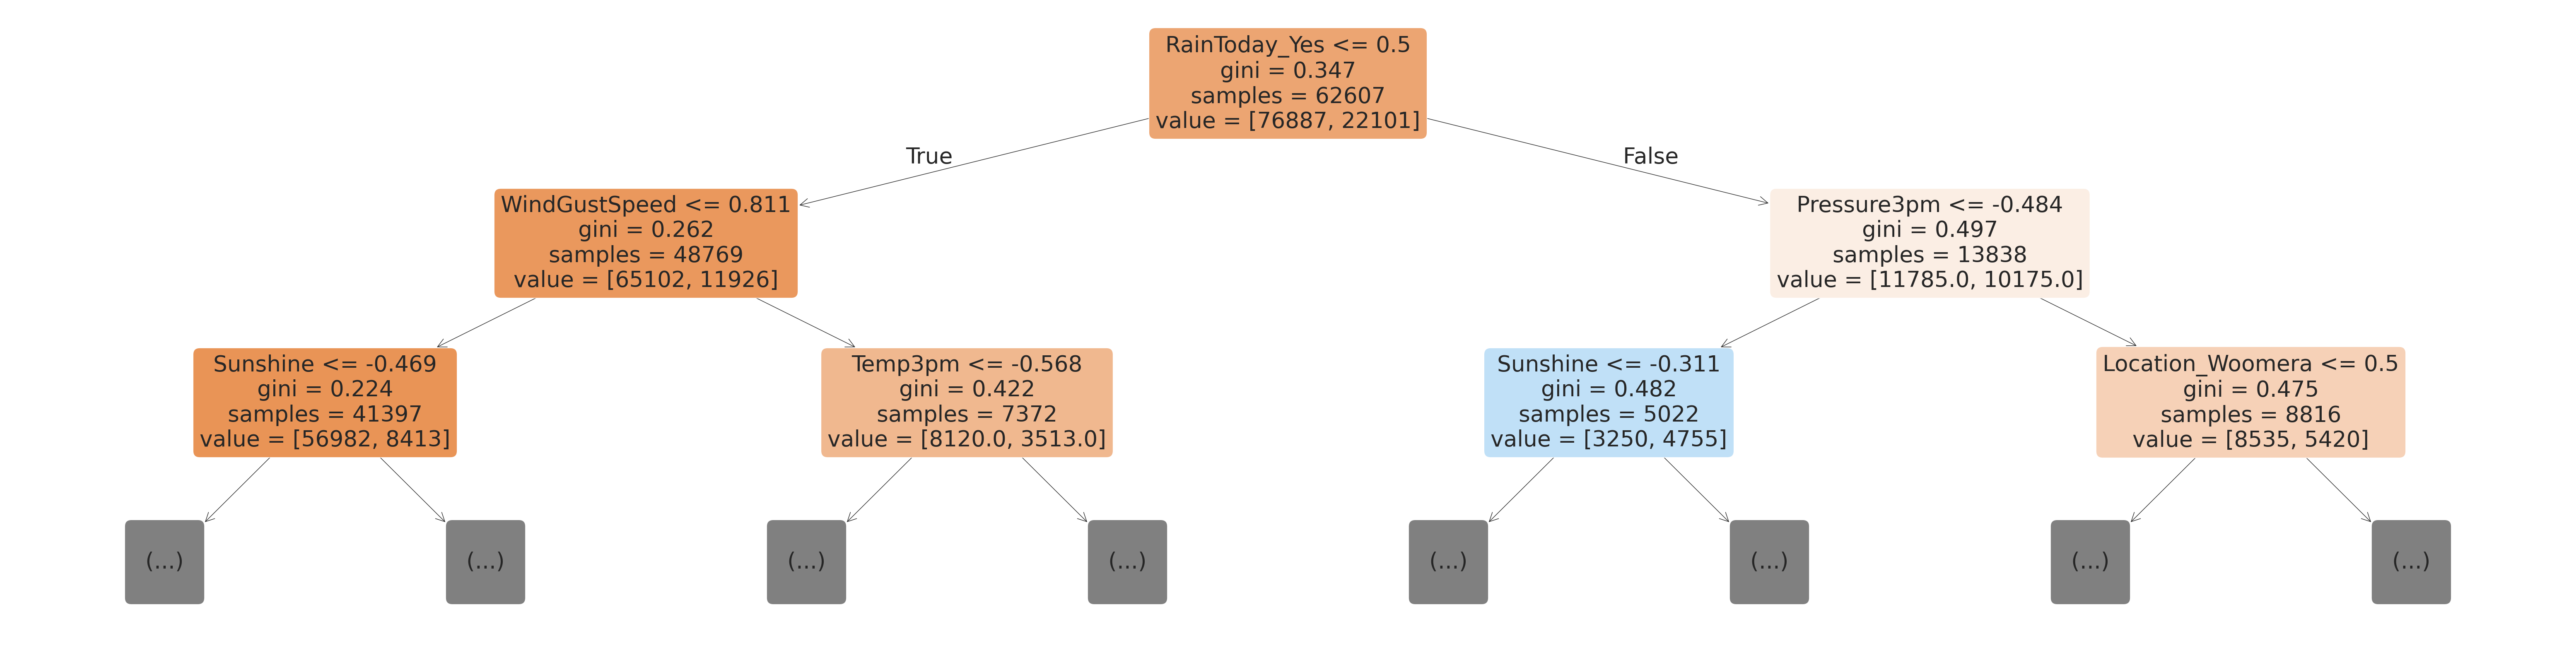

In [75]:
plt.figure(figsize=(80,20))
plot_tree(model.estimators_[0],max_depth=2,feature_names=x_train.columns,filled=True ,rounded=True)
plt.show()

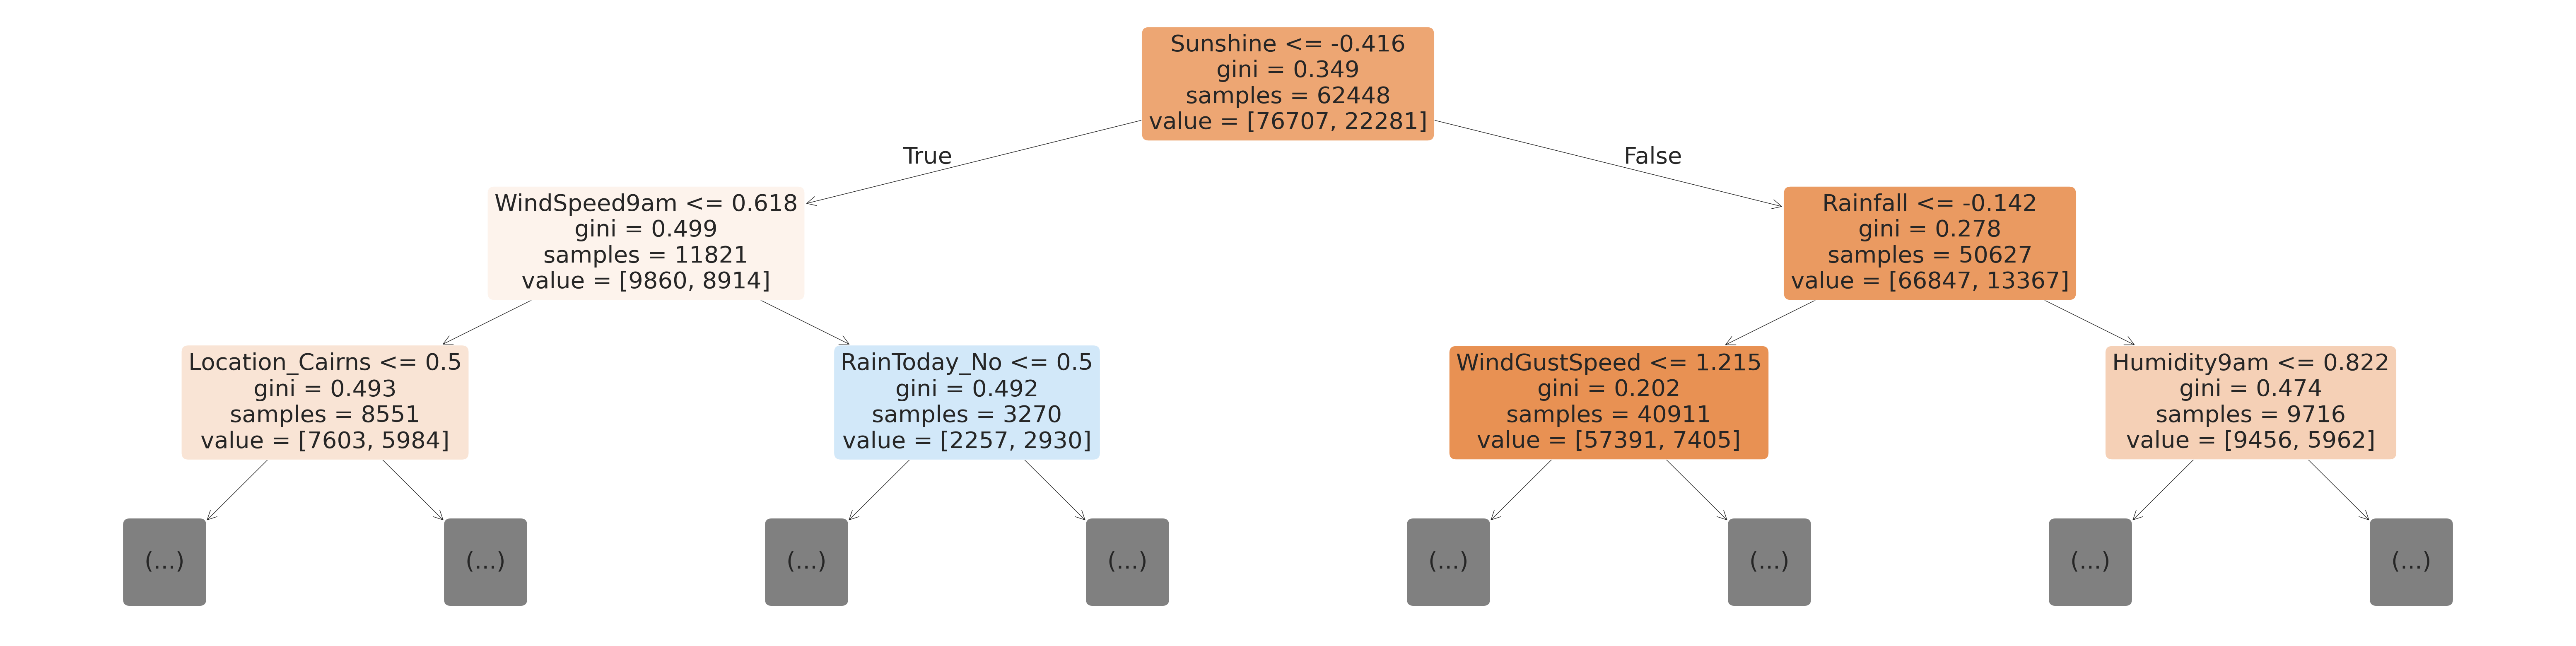

In [76]:
plt.figure(figsize=(80,20))
plot_tree(model.estimators_[15],max_depth=2,feature_names=x_train.columns,filled=True ,rounded=True)
plt.show()

In [77]:
important_df=pd.DataFrame({
    "features":x_train.columns,
    "importance": model.feature_importances_
}).sort_values("importance",ascending=False)

In [78]:
important_df.head(10)

,features,importance
112,Humidity3pm,0.137732
107,Sunshine,0.054213
114,Pressure3pm,0.051183
113,Pressure9am,0.050734
111,Humidity9am,0.050700
118,Temp3pm,0.046647
108,WindGustSpeed,0.046486
105,Rainfall,0.044381
103,MinTemp,0.042333
104,MaxTemp,0.041356


<Axes: xlabel='importance', ylabel='features'>

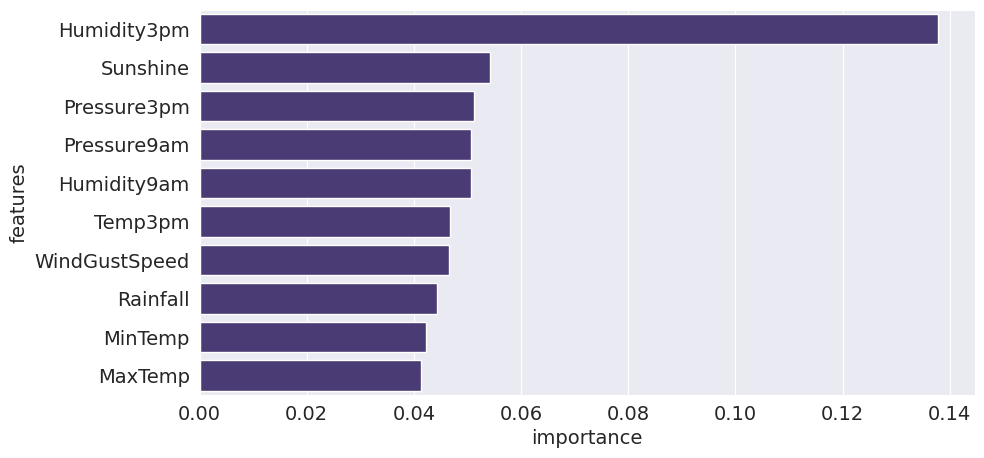

In [79]:
sns.barplot(important_df.head(10),x="importance",y="features")

# Hyperparameter Turning In Random Forest

In [80]:
base_model=RandomForestClassifier(random_state=42,n_jobs=-1).fit(x_train,train_targets)

In [81]:
base_train_acc=model.score(x_train,train_targets)
base_val_acc=base_model.score(x_val,val_targets)

In [82]:
base_accs=base_train_acc,base_val_acc
base_accs

(0.9999494888269285, 0.8559572862863444)

#n_estimator

In [83]:
"""def Best_estimator(x):
 model=RandomForestClassifier(random_state=42,n_job=-1,n_estimator=x).fit(x_train,train_targets)"""


'def Best_estimator(x):\n model=RandomForestClassifier(random_state=42,n_job=-1,n_estimator=x).fit(x_train,train_targets)'

In [84]:
python function?

Object `function` not found.


In [85]:
def test_params(**params):
  model=RandomForestClassifier(random_state=42,n_jobs=-1,**params).fit(x_train,train_targets)
  return model.score(x_train,train_targets),model.score(x_val,val_targets)

In [86]:
test_params(n_estimators=10,max_depth=5,max_leaf_nodes=1024)

(0.8229886450882935, 0.826475538274041)

In [87]:
test_params(max_depth=25)

(0.9768961894371034, 0.856363530845569)

In [88]:
test_params(max_leaf_nodes=2**20)

(0.9999494888269285, 0.8561313910974406)

 Max_feature

In [89]:
x_train.columns

Index(['Location_Adelaide', 'Location_Albany', 'Location_Albury',
       'Location_AliceSprings', 'Location_BadgerysCreek', 'Location_Ballarat',
       'Location_Bendigo', 'Location_Brisbane', 'Location_Cairns',
       'Location_Canberra',
       ...
       'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm',
       'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am',
       'Temp3pm'],
      dtype='object', length=119)

In [118]:
model=RandomForestClassifier(
    n_jobs=-1,
    random_state=42,
    max_depth=25,
    max_leaf_nodes=2**20,
    n_estimators=100,
    max_features=0.5,
    min_samples_leaf=12,
    min_samples_split=12,
    bootstrap=True,
    oob_score=True,
    min_impurity_decrease=0.001,
    class_weight={"No":1,
                  "Yes":2}

)

In [124]:
train_targets = train_targets.astype(str)
model.fit(x_train,train_targets)

RandomForestClassifier(class_weight={'No': 1, 'Yes': 2}, max_depth=25,
                       max_features=0.5, max_leaf_nodes=1048576,
                       min_impurity_decrease=0.001, min_samples_leaf=12,
                       min_samples_split=12, n_jobs=-1, oob_score=True,
                       random_state=42)

In [120]:
model.score(x_train,train_targets),model.score(x_val,val_targets)

(0.8318483048450317, 0.8322790319772503)

In [122]:
model.score(x_test,test_targets)

0.8214368214368214

# Making prediction on new Input

In [126]:
def single_values (model,new_input):
  new_input=pd.DataFrame([new_input])
  new_input[numerical_cols]=imputer.transform(new_input[numerical_cols])
  new_input[numerical_cols]=scaler.transform(new_input[numerical_cols])
  new_input[encoder_col]=Encoder.transform(new_input[categorical_cols])
  x_new=new_input[encoder_col+numerical_cols]
  pred=model.predict(x_new)[0]
  prob=model.predict_proba(x_new)[0]
  return {
      "prediction":pred,
      "probability":prob
  }

In [127]:
'''import ipywidgets as widgets
from IPython.display import display, clear_output

# Get unique values for categorical columns
location_options = list(raw_df['Location'].dropna().unique())
windgustdir_options = list(raw_df['WindGustDir'].dropna().unique())
winddir9am_options = list(raw_df['WindDir9am'].dropna().unique())
winddir3pm_options = list(raw_df['WindDir3pm'].dropna().unique())
raintoday_options = list(raw_df['RainToday'].dropna().unique())

# Create input widgets for each feature
input_widgets = {
    'Location': widgets.Dropdown(options=location_options, description='Location'),
    'MinTemp': widgets.FloatText(description='MinTemp'),
    'MaxTemp': widgets.FloatText(description='MaxTemp'),
    'Rainfall': widgets.FloatText(description='Rainfall'),
    'Evaporation': widgets.FloatText(description='Evaporation'),
    'Sunshine': widgets.FloatText(description='Sunshine'),
    'WindGustDir': widgets.Dropdown(options=windgustdir_options, description='WindGustDir'),
    'WindGustSpeed': widgets.FloatText(description='WindGustSpeed'),
    'WindDir9am': widgets.Dropdown(options=winddir9am_options, description='WindDir9am'),
    'WindDir3pm': widgets.Dropdown(options=winddir3pm_options, description='WindDir3pm'),
    'WindSpeed9am': widgets.FloatText(description='WindSpeed9am'),
    'WindSpeed3pm': widgets.FloatText(description='WindSpeed3pm'),
    'Humidity9am': widgets.FloatText(description='Humidity9am'),
    'Humidity3pm': widgets.FloatText(description='Humidity3pm'),
    'Pressure9am': widgets.FloatText(description='Pressure9am'),
    'Pressure3pm': widgets.FloatText(description='Pressure3pm'),
    'Cloud9am': widgets.FloatText(description='Cloud9am'),
    'Cloud3pm': widgets.FloatText(description='Cloud3pm'),
    'Temp9am': widgets.FloatText(description='Temp9am'),
    'Temp3pm': widgets.FloatText(description='Temp3pm'),
    'RainToday': widgets.Dropdown(options=raintoday_options, description='RainToday')
}

# Arrange widgets in a VBox
form_items = [widgets.HBox([widgets.Label(value=f'{name}:'), widget]) for name, widget in input_widgets.items()]
input_form = widgets.VBox(form_items)

# Create a button for prediction
predict_button = widgets.Button(description='Predict Rain Tomorrow')
output_area = widgets.Output()

def on_predict_button_clicked(b):
    with output_area:
        clear_output()
        new_data = {}
        for feature, widget in input_widgets.items():
            new_data[feature] = widget.value

        # Call the single_values function defined earlier
        prediction_result = single_values(model, new_data)

        print(f"Prediction: {prediction_result['prediction']}")
        print(f"Probability: {prediction_result['probability']}")

predict_button.on_click(on_predict_button_clicked)

display(input_form, predict_button, output_area)'''

'import ipywidgets as widgets\nfrom IPython.display import display, clear_output\n\n# Get unique values for categorical columns\nlocation_options = list(raw_df[\'Location\'].dropna().unique())\nwindgustdir_options = list(raw_df[\'WindGustDir\'].dropna().unique())\nwinddir9am_options = list(raw_df[\'WindDir9am\'].dropna().unique())\nwinddir3pm_options = list(raw_df[\'WindDir3pm\'].dropna().unique())\nraintoday_options = list(raw_df[\'RainToday\'].dropna().unique())\n\n# Create input widgets for each feature\ninput_widgets = {\n    \'Location\': widgets.Dropdown(options=location_options, description=\'Location\'),\n    \'MinTemp\': widgets.FloatText(description=\'MinTemp\'),\n    \'MaxTemp\': widgets.FloatText(description=\'MaxTemp\'),\n    \'Rainfall\': widgets.FloatText(description=\'Rainfall\'),\n    \'Evaporation\': widgets.FloatText(description=\'Evaporation\'),\n    \'Sunshine\': widgets.FloatText(description=\'Sunshine\'),\n    \'WindGustDir\': widgets.Dropdown(options=windgustdir

In [ ]:
aussie_rain={
    "model":model,
    "imputer":imputer,
    "scaler":scaler,
    "Encoder":Encoder,
    "input_cols":input_cols,
    "target_col":target_col,
    "encoder_col":encoder_col,
    "numerical_cols":numerical_cols,
    "categorical_cols":categorical_cols
}